In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_columns', None) 

# 1. Data Exploration

In [2]:
#Data Reading

In [ ]:
semiconductor_trade= pd.read_csv(r"../data/raw/\01_semiconductor_trade_flows.csv")
trade_sanctions_export_controls= pd.read_csv(r"../data/raw/\02_trade_sanctions_export_controls.csv")
national_ai_infrastructure_budgets= pd.read_csv(r"../data/raw/\03_national_ai_infrastructure_budgets.csv")
energy_grid_capacity= pd.read_csv(r"../data/raw/\04_energy_grid_capacity.csv")
macroeconomic_indicators= pd.read_csv(r"../data/raw/\05_macroeconomic_indicators.csv")
company_profiles= pd.read_csv(r"../data/raw/\06_company_profiles.csv")
df1= semiconductor_trade.copy()
df2= trade_sanctions_export_controls.copy()
df3= national_ai_infrastructure_budgets.copy()
df4= energy_grid_capacity.copy()
df5= macroeconomic_indicators.copy()
df6= company_profiles.copy()

## 1. semiconductor_trade

In [4]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5656 entries, 0 to 5655
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   trade_id                  5656 non-null   object 
 1   year                      5656 non-null   int64  
 2   quarter                   5656 non-null   int64  
 3   year_quarter              5656 non-null   object 
 4   exporter_country_code     5656 non-null   object 
 5   exporter_country          5656 non-null   object 
 6   exporter_region           5656 non-null   object 
 7   importer_country_code     5656 non-null   object 
 8   importer_country          5656 non-null   object 
 9   importer_region           5656 non-null   object 
 10  hardware_type             5656 non-null   object 
 11  hardware_category         5656 non-null   object 
 12  volume_units              5656 non-null   int64  
 13  trade_value_usd_millions  5656 non-null   float64
 14  primary_

In [5]:
df1['trade_id']=df1['trade_id'].astype('string')
df1['year_quarter']=df1['year_quarter'].astype('string')
df1['exporter_country_code']=df1['exporter_country_code'].astype('string')
df1['exporter_country']=df1['exporter_country'].astype('string')
df1['exporter_region']=df1['exporter_region'].astype('string')
df1['importer_country_code']=df1['importer_country_code'].astype('string')
df1['importer_country']=df1['importer_country'].astype('string')
df1['importer_region']=df1['importer_region'].astype('string')
df1['hardware_type']=df1['hardware_type'].astype('string')
df1['hardware_category']=df1['hardware_category'].astype('category')
df1['primary_supplier']=df1['primary_supplier'].astype('string')
df1['trade_route']=df1['trade_route'].astype('string')
df1['geopolitical_sensitivity']=pd.Categorical(df1['geopolitical_sensitivity'],categories=['Low','Medium','High'],ordered=True)
df1['data_source']=df1['data_source'].astype('string')
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5656 entries, 0 to 5655
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   trade_id                  5656 non-null   string  
 1   year                      5656 non-null   int64   
 2   quarter                   5656 non-null   int64   
 3   year_quarter              5656 non-null   string  
 4   exporter_country_code     5656 non-null   string  
 5   exporter_country          5656 non-null   string  
 6   exporter_region           5656 non-null   string  
 7   importer_country_code     5656 non-null   string  
 8   importer_country          5656 non-null   string  
 9   importer_region           5656 non-null   string  
 10  hardware_type             5656 non-null   string  
 11  hardware_category         5656 non-null   category
 12  volume_units              5656 non-null   int64   
 13  trade_value_usd_millions  5656 non-null   float6

In [6]:
df1.shape

(5656, 23)

In [7]:
df1['geopolitical_sensitivity'].value_counts()

geopolitical_sensitivity
Low       3036
High      1872
Medium     748
Name: count, dtype: int64

In [8]:
df1.sample(10)

,trade_id,year,quarter,year_quarter,exporter_country_code,exporter_country,exporter_region,importer_country_code,importer_country,importer_region,hardware_type,hardware_category,volume_units,trade_value_usd_millions,primary_supplier,trade_route,export_control_applied,restriction_factor,geopolitical_sensitivity,geo_risk_score_exporter,geo_risk_score_importer,data_source,is_synthetic
3517,TF003518,2019,2,2019-Q2,KR,South Korea,Asia-Pacific,DE,Germany,Europe,Advanced_Logic_Chip,Advanced,2029,108.70,Intel Foundry Services,Trans-Pacific / Suez,0,1.0,Low,5.03,2.33,UN Comtrade/WITS/SIA Reports,0
819,TF000820,2021,4,2021-Q4,TW,Taiwan,Asia-Pacific,FR,France,Europe,Advanced_Logic_Chip,Advanced,2472,148.36,Intel Foundry Services,Trans-Pacific / Suez,0,1.0,Low,8.45,2.77,UN Comtrade/WITS/SIA Reports,0
3416,TF003417,2016,1,2016-Q1,KR,South Korea,Asia-Pacific,DE,Germany,Europe,DRAM,Standard,1579,84.62,Micron,Trans-Pacific / Suez,0,1.0,Low,4.80,2.29,UN Comtrade/WITS/SIA Reports,0
5643,TF005644,2022,4,2022-Q4,FR,France,Europe,CN,China,Asia-Pacific,Semiconductor_Equipment,Standard,503,251.70,Lam Research,Trans-Pacific / Suez,0,1.0,High,2.85,8.10,UN Comtrade/WITS/SIA Reports,0
5217,TF005218,2015,2,2015-Q2,AE,United Arab Emirates,Middle East,IN,India,South Asia,AI_Accelerator,Advanced,630,36.80,Huawei Ascend,Middle-East/South-Asia Corridor,0,1.0,Low,4.35,5.01,UN Comtrade/WITS/SIA Reports,0
735,TF000736,2022,4,2022-Q4,TW,Taiwan,Asia-Pacific,AE,United Arab Emirates,Middle East,Advanced_Logic_Chip,Advanced,2366,133.10,TSMC,Middle-East/South-Asia Corridor,0,1.0,Medium,8.63,4.41,UN Comtrade/WITS/SIA Reports,0
1610,TF001611,2021,3,2021-Q3,US,United States,North America,FR,France,Europe,AI_Accelerator,Advanced,8406,513.72,Intel Gaudi,Asia-Pacific Maritime,0,1.0,Low,3.45,2.84,UN Comtrade/WITS/SIA Reports,0
3337,TF003338,2018,2,2018-Q2,KR,South Korea,Asia-Pacific,AE,United Arab Emirates,Middle East,DRAM,Standard,1728,86.43,SK Hynix,Middle-East/South-Asia Corridor,0,1.0,Medium,4.80,4.34,UN Comtrade/WITS/SIA Reports,0
4502,TF004503,2023,3,2023-Q3,CN,China,Asia-Pacific,IN,India,South Asia,Consumer_Chip,Standard,7259,362.97,Allwinner,Asia-Pacific Maritime,0,1.0,High,8.17,4.86,UN Comtrade/WITS/SIA Reports,0
3694,TF003695,2019,3,2019-Q3,JP,Japan,Asia-Pacific,KR,South Korea,Asia-Pacific,Semiconductor_Equipment,Standard,552,287.72,ASML,Asia-Pacific Maritime,0,1.0,Low,3.04,4.92,UN Comtrade/WITS/SIA Reports,0


In [9]:
df1['hardware_type'].value_counts()

hardware_type
Semiconductor_Equipment    1188
Advanced_Logic_Chip         748
AI_Accelerator              691
Consumer_Chip               616
DRAM                        528
GPU_High_End                427
DUV_Lithography_Machine     342
NAND_Flash                  264
Chemical_Materials          264
Telecom_Chip                220
HBM_Memory                  176
EUV_Lithography_Machine     104
EDA_Software                 44
Surveillance_Chip            44
Name: count, dtype: Int64

In [10]:
q1=df1['trade_value_usd_millions'].quantile(0.25)
q3=df1['trade_value_usd_millions'].quantile(0.75)
iqr=q3-q1
ub=iqr+(q3*1.5)
lb=iqr-(q1*1.5)
print(ub)
print(lb)

1196.5849999999998
186.8337499999999


In [11]:
outliers=df1[(df1['trade_value_usd_millions']>ub) | (df1['trade_value_usd_millions']<lb)]
outliers

,trade_id,year,quarter,year_quarter,exporter_country_code,exporter_country,exporter_region,importer_country_code,importer_country,importer_region,hardware_type,hardware_category,volume_units,trade_value_usd_millions,primary_supplier,trade_route,export_control_applied,restriction_factor,geopolitical_sensitivity,geo_risk_score_exporter,geo_risk_score_importer,data_source,is_synthetic
25,TF000026,2021,2,2021-Q2,TW,Taiwan,Asia-Pacific,US,United States,North America,Advanced_Logic_Chip,Advanced,21943,1280.02,TSMC,Trans-Pacific / Suez,0,1.0,Low,8.53,3.25,UN Comtrade/WITS/SIA Reports,0
26,TF000027,2021,3,2021-Q3,TW,Taiwan,Asia-Pacific,US,United States,North America,Advanced_Logic_Chip,Advanced,21059,1228.47,Intel Foundry Services,Trans-Pacific / Suez,0,1.0,Low,8.33,3.49,UN Comtrade/WITS/SIA Reports,0
29,TF000030,2022,2,2022-Q2,TW,Taiwan,Asia-Pacific,US,United States,North America,Advanced_Logic_Chip,Advanced,24065,1403.80,Intel Foundry Services,Trans-Pacific / Suez,0,1.0,Low,8.82,3.43,UN Comtrade/WITS/SIA Reports,0
30,TF000031,2022,3,2022-Q3,TW,Taiwan,Asia-Pacific,US,United States,North America,Advanced_Logic_Chip,Advanced,22186,1294.23,Samsung Foundry,Trans-Pacific / Suez,0,1.0,Low,8.76,3.52,UN Comtrade/WITS/SIA Reports,0
31,TF000032,2022,4,2022-Q4,TW,Taiwan,Asia-Pacific,US,United States,North America,Advanced_Logic_Chip,Advanced,21820,1272.85,TSMC,Trans-Pacific / Suez,0,1.0,Low,8.78,3.44,UN Comtrade/WITS/SIA Reports,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5616,TF005617,2016,1,2016-Q1,FR,France,Europe,CN,China,Asia-Pacific,Semiconductor_Equipment,Standard,302,151.39,Lam Research,Trans-Pacific / Suez,0,1.0,High,2.66,7.45,UN Comtrade/WITS/SIA Reports,0
5619,TF005620,2016,4,2016-Q4,FR,France,Europe,CN,China,Asia-Pacific,Semiconductor_Equipment,Standard,316,158.10,Lam Research,Trans-Pacific / Suez,0,1.0,High,2.87,7.34,UN Comtrade/WITS/SIA Reports,0
5620,TF005621,2017,1,2017-Q1,FR,France,Europe,CN,China,Asia-Pacific,Semiconductor_Equipment,Standard,351,176.00,ASML,Trans-Pacific / Suez,0,1.0,High,2.77,7.29,UN Comtrade/WITS/SIA Reports,0
5624,TF005625,2018,1,2018-Q1,FR,France,Europe,CN,China,Asia-Pacific,Semiconductor_Equipment,Standard,351,175.99,Applied Materials,Trans-Pacific / Suez,0,1.0,High,2.74,7.26,UN Comtrade/WITS/SIA Reports,0


In [12]:
outliers.shape

(2740, 23)

<Axes: xlabel='year', ylabel='geo_risk_score_exporter'>

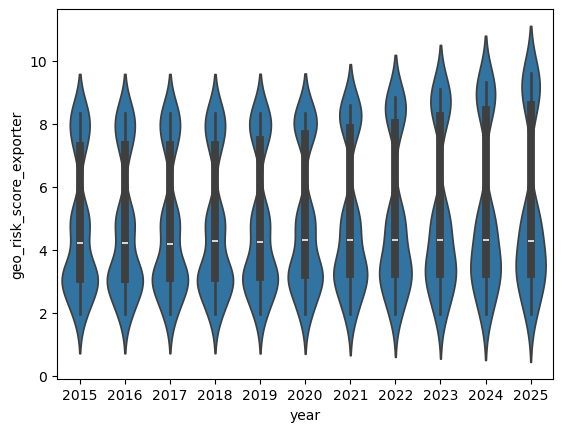

In [13]:
sns.violinplot(data=df1,x='year',y='geo_risk_score_exporter')

In [14]:
#Insight:
#Risw has been increased since the begining of 2021, Same Period with the Russion-Okranien conflict , also it kept increasing since the 7th of October 2023 till now with the American-Iranian Conflict

In [15]:
Global_Semiconductor_Exports=df1['trade_value_usd_millions'].sum()
Total_Volume=df1['volume_units'].sum()
print('Total_Volume= ',(Total_Volume/1000000).round(2), 'M unit')
Trade_Value= (Global_Semiconductor_Exports/1000000).round(2)
print('Trade_Value = ','$',Trade_Value,'T')
Trade_records= df1['trade_id'].nunique()
print('Trade_records = ',Trade_records)

Total_Volume=  31.42 M unit
Trade_Value =  $ 3.91 T
Trade_records =  5656


In [16]:
Waterway_trade_share= df1.groupby('trade_route')[['volume_units','trade_value_usd_millions']].sum().sort_values(by='trade_value_usd_millions',ascending=False)
Waterway_trade_share['Volume_share']=(Waterway_trade_share['volume_units']/Total_Volume*100)
Waterway_trade_share['Value_share']=(Waterway_trade_share['trade_value_usd_millions']/Global_Semiconductor_Exports*100)
Waterway_trade_share

,volume_units,trade_value_usd_millions,Volume_share,Value_share
trade_route,,,,
Trans-Pacific / Suez,15126137,2441183.53,48.137885,62.485998
Asia-Pacific Maritime,12540335,1051780.24,39.908749,26.921998
Intra-Atlantic,60792,210703.20,0.193466,5.393286
Middle-East/South-Asia Corridor,3695257,203101.91,11.759900,5.198718


In [17]:
fig = px.pie(df1, values="trade_value_usd_millions" , names="trade_route", title="Waterway_trade_share")
fig.show()

In [18]:
df1.describe(include='number')

,year,quarter,volume_units,trade_value_usd_millions,export_control_applied,restriction_factor,geo_risk_score_exporter,geo_risk_score_importer,is_synthetic
count,5656.000000,5656.000000,5656.000000,5656.000000,5656.000000,5656.000000,5656.000000,5656.000000,5656.000000
mean,2019.964993,2.499116,5555.608380,690.730000,0.016620,0.990417,4.883674,5.128992,0.178218
std,3.157495,1.117974,8862.033951,1467.124774,0.127852,0.074718,2.291312,2.028545,0.382730
min,2015.000000,1.000000,5.000000,16.090000,0.000000,0.250000,1.950000,2.250000,0.000000
25%,2017.000000,1.000000,776.750000,138.952500,0.000000,1.000000,3.140000,3.280000,0.000000
50%,2020.000000,2.000000,2747.000000,246.670000,0.000000,1.000000,4.275000,4.930000,0.000000
75%,2023.000000,3.000000,6083.250000,534.215000,0.000000,1.000000,7.460000,7.400000,0.000000
max,2025.000000,4.000000,112572.000000,21840.980000,1.000000,1.000000,9.600000,9.600000,1.000000


In [19]:
df1['exporter_country'].nunique()

11

In [20]:
exp_values= df1.groupby('exporter_country')['trade_value_usd_millions'].agg(['sum','mean'])
exp_values= exp_values.rename(columns={'sum':'exp_value', 'mean':'exp_mean'})
exp_values['Value_share_pct']=(exp_values['exp_value']/Global_Semiconductor_Exports)*100
exp_values.sort_values(by='exp_value',ascending=False)

,exp_value,exp_mean,Value_share_pct
exporter_country,,,
Netherlands,1645222.44,3688.839552,42.112101
Taiwan,615397.55,635.741271,15.752085
United States,527323.34,421.858672,13.497685
Japan,453537.78,736.262630,11.609025
South Korea,385832.36,438.445864,9.875997
China,143557.55,233.047971,3.674585
Germany,85395.32,277.257532,2.185830
United Arab Emirates,17667.99,80.309045,0.452240
France,16594.78,125.718030,0.424770


In [21]:
df1['importer_country'].nunique()

11

In [22]:
imp_values= df1.groupby('importer_country')['trade_value_usd_millions'].agg(['sum','mean'])
imp_values = imp_values.rename(columns={'sum':'import_value', 'mean':'import_mean'})


In [23]:
semi_trade_balance= pd.concat([exp_values,imp_values],axis=1).fillna(0)
semi_trade_balance['Trade_Balance']=semi_trade_balance['exp_value']-semi_trade_balance['import_value']
semi_trade_balance["Balance_pct_of_flows"] = (
    semi_trade_balance["Trade_Balance"] / (semi_trade_balance["exp_value"] + semi_trade_balance["import_value"]) * 100
).round(1)
semi_trade_balance.sort_values(by='Balance_pct_of_flows',ascending=False)

,exp_value,exp_mean,Value_share_pct,import_value,import_mean,Trade_Balance,Balance_pct_of_flows
Netherlands,1645222.44,3688.839552,42.112101,0.00,0.000000,1645222.44,100.0
Japan,453537.78,736.262630,11.609025,302341.44,763.488485,151196.34,20.0
United States,527323.34,421.858672,13.497685,631740.65,844.573061,-104417.31,-9.0
Taiwan,615397.55,635.741271,15.752085,796494.41,1508.512140,-181096.86,-12.8
Germany,85395.32,277.257532,2.185830,133895.57,253.590095,-48500.25,-22.1
South Korea,385832.36,438.445864,9.875997,666073.41,1513.803205,-280241.05,-26.6
France,16594.78,125.718030,0.424770,47913.96,272.238409,-31319.18,-48.6
United Arab Emirates,17667.99,80.309045,0.452240,92716.24,191.562479,-75048.25,-68.0
China,143557.55,233.047971,3.674585,800211.50,1099.191621,-656653.95,-69.6
Saudi Arabia,6208.66,70.552955,0.158921,61053.09,198.224318,-54844.43,-81.5


In [24]:
px.histogram(df1,x='year',y='trade_value_usd_millions',barmode='group',color='exporter_country')

In [25]:
px.histogram(df1,x='year',y='trade_value_usd_millions',barmode='group',color='importer_country')

In [26]:
top5_suppliers= df1.groupby('primary_supplier')['trade_value_usd_millions'].agg(('sum')).sort_values(ascending=False).nlargest(5)
top5_suppliers

primary_supplier
ASML        1177313.72
Canon        417523.52
Nikon        410907.29
Micron       144520.84
SK Hynix     141541.13
Name: trade_value_usd_millions, dtype: float64

In [27]:
hardware_trade= df1.groupby('hardware_type')['trade_value_usd_millions'].sum().sort_values(ascending=False).reset_index()
hardware_trade

,hardware_type,trade_value_usd_millions
0,DUV_Lithography_Machine,1255720.91
1,EUV_Lithography_Machine,684073.02
2,AI_Accelerator,337781.76
3,Semiconductor_Equipment,310185.36
4,GPU_High_End,284097.94
5,Advanced_Logic_Chip,267261.28
6,DRAM,214824.05
7,NAND_Flash,164236.00
8,Consumer_Chip,135859.21
9,HBM_Memory,105128.11


In [28]:
df1['hardware_type'].nunique()

14

## 2. trade_sanctions_export_controls

In [29]:
df2.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 987 entries, 0 to 986
Data columns (total 19 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   sanction_id                 987 non-null    object 
 1   date_implemented            987 non-null    object 
 2   year                        987 non-null    int64  
 3   month                       987 non-null    int64  
 4   imposing_country_code       987 non-null    object 
 5   imposing_country            987 non-null    object 
 6   imposing_region             987 non-null    object 
 7   target_country_code         987 non-null    object 
 8   target_country              987 non-null    object 
 9   restriction_type            987 non-null    object 
 10  affected_technology         987 non-null    object 
 11  severity_level              987 non-null    int64  
 12  description                 987 non-null    object 
 13  source_reference            987 non

In [30]:
df2.shape

(987, 19)

In [31]:
df2.sample(20)

,sanction_id,date_implemented,year,month,imposing_country_code,imposing_country,imposing_region,target_country_code,target_country,restriction_type,affected_technology,severity_level,description,source_reference,is_retaliatory,multilateral,status,economic_impact_usd_bn_est,is_synthetic
438,SC0449,2021-12-14,2021,12,EU,EU,Europe,SA,Saudi Arabia,Export_Ban,Quantum_Computing,1,[Synthetic] Export_Ban on Quantum_Computing – ...,Synthetic/Regulatory Pattern Estimate,1,0,Active,6.27,1
143,SC0159,2018-07-20,2018,7,KR,South Korea,Asia-Pacific,SA,Saudi Arabia,Data_Localization,Semiconductor_Equipment,5,[Synthetic] Data_Localization on Semiconductor...,Synthetic/Regulatory Pattern Estimate,1,0,Active,23.14,1
446,SC0479,2022-01-02,2022,1,JP,Japan,Asia-Pacific,TW,Taiwan,Technology_Transfer_Ban,Semiconductor_Equipment,5,[Synthetic] Technology_Transfer_Ban on Semicon...,Synthetic/Regulatory Pattern Estimate,1,1,Active,26.13,1
591,SC0622,2023-02-13,2023,2,KR,South Korea,Asia-Pacific,AE,United Arab Emirates,Export_Ban,Cloud_AI_Services,4,[Synthetic] Export_Ban on Cloud_AI_Services – ...,Synthetic/Regulatory Pattern Estimate,1,0,Active,47.59,1
131,SC0163,2018-05-26,2018,5,NL,Netherlands,Europe,SA,Saudi Arabia,Export_Ban,Semiconductor_Equipment,3,[Synthetic] Export_Ban on Semiconductor_Equipm...,Synthetic/Regulatory Pattern Estimate,1,0,Active,26.60,1
239,SC0009,2019-08-28,2019,8,JP,Japan,Asia-Pacific,KR,South Korea,Export_Ban,Dual_use_materials_1120_items,4,Japan removes South Korea from preferred white...,METI Japan 2019,0,0,Active,34.74,0
467,SC0588,2022-03-07,2022,3,DE,Germany,Europe,AE,United Arab Emirates,Export_Ban,GPU_High_End,5,[Synthetic] Export_Ban on GPU_High_End – DE ta...,Synthetic/Regulatory Pattern Estimate,1,0,Active,29.31,1
137,SC0173,2018-06-05,2018,6,EU,EU,Europe,SA,Saudi Arabia,Export_Ban,Cloud_AI_Services,2,[Synthetic] Export_Ban on Cloud_AI_Services – ...,Synthetic/Regulatory Pattern Estimate,0,1,Active,17.41,1
800,SC0803,2024-07-26,2024,7,EU,EU,Europe,IN,India,Entity_Blacklist,HBM_Memory,2,[Synthetic] Entity_Blacklist on HBM_Memory – E...,Synthetic/Regulatory Pattern Estimate,0,0,Active,10.83,1
753,SC0825,2024-03-22,2024,3,JP,Japan,Asia-Pacific,RU,RU,Tariff,Dual_Use_Electronics,1,[Synthetic] Tariff on Dual_Use_Electronics – J...,Synthetic/Regulatory Pattern Estimate,0,0,Active,2.24,1


In [32]:
df2['target_country'].value_counts()

target_country
China                   141
Taiwan                  128
RU                      127
India                   124
United Arab Emirates    123
Saudi Arabia            120
Pakistan                107
IR                      103
United States             6
GLOBAL                    5
South Korea               3
Name: count, dtype: int64

In [33]:
Global= df2[df2['target_country']=='GLOBAL']
Global

,sanction_id,date_implemented,year,month,imposing_country_code,imposing_country,imposing_region,target_country_code,target_country,restriction_type,affected_technology,severity_level,description,source_reference,is_retaliatory,multilateral,status,economic_impact_usd_bn_est,is_synthetic
425,SC0016,2021-11-01,2021,11,CN,China,Asia-Pacific,GLOBAL,GLOBAL,Data_Localization,Personal_data_AI_training_data,3,China PIPL Personal Information Protection Law...,NPC China 2021,0,0,Active,28.56,0
517,SC0017,2022-08-09,2022,8,US,United States,North America,GLOBAL,GLOBAL,Export_Ban,Semiconductor_manufacturing_advanced_chips,5,CHIPS and Science Act signed – domestic invest...,US Congress 2022,0,0,Active,25.44,0
662,SC0032,2023-08-01,2023,8,CN,China,Asia-Pacific,GLOBAL,GLOBAL,Data_Localization,AI_generated_content_training_data,3,China Generative AI regulations take effect,CAC China 2023,0,0,Active,33.08,0
805,SC0038,2024-08-01,2024,8,EU,EU,Multi-Regional,GLOBAL,GLOBAL,Data_Localization,AI_systems_high_risk_applications,4,EU AI Act enters into force,EU Parliament 2024,0,1,Active,53.35,0
856,SC0040,2025-01-13,2025,1,US,United States,North America,GLOBAL,GLOBAL,Export_Ban,AI_chips_diffusion_rule_country_tiers,5,Biden AI Diffusion Rule – tiered country AI ch...,BIS Jan 2025,0,0,Active,35.03,0


In [34]:
pk= df2[df2['target_country']=='Pakistan']
pk

,sanction_id,date_implemented,year,month,imposing_country_code,imposing_country,imposing_region,target_country_code,target_country,restriction_type,affected_technology,severity_level,description,source_reference,is_retaliatory,multilateral,status,economic_impact_usd_bn_est,is_synthetic
17,SC0054,2015-07-20,2015,7,DE,Germany,Europe,PK,Pakistan,Tariff,Gallium_Germanium,2,[Synthetic] Tariff on Gallium_Germanium – DE t...,Synthetic/Regulatory Pattern Estimate,0,1,Active,22.26,1
22,SC0051,2015-08-24,2015,8,EU,EU,Europe,PK,Pakistan,Data_Localization,Semiconductor_Equipment,3,[Synthetic] Data_Localization on Semiconductor...,Synthetic/Regulatory Pattern Estimate,1,1,Active,8.56,1
23,SC0059,2015-08-18,2015,8,US,United States,North America,PK,Pakistan,Export_Ban,GPU_High_End,4,[Synthetic] Export_Ban on GPU_High_End – US ta...,Synthetic/Regulatory Pattern Estimate,0,0,Active,15.85,1
32,SC0043,2015-12-17,2015,12,DE,Germany,Europe,PK,Pakistan,Technology_Transfer_Ban,HBM_Memory,1,[Synthetic] Technology_Transfer_Ban on HBM_Mem...,Synthetic/Regulatory Pattern Estimate,0,1,Active,10.94,1
40,SC0080,2016-04-21,2016,4,NL,Netherlands,Europe,PK,Pakistan,License_Requirement,HBM_Memory,1,[Synthetic] License_Requirement on HBM_Memory ...,Synthetic/Regulatory Pattern Estimate,0,0,Active,10.67,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
889,SC0922,2025-04-07,2025,4,FR,France,Europe,PK,Pakistan,Data_Localization,Dual_Use_Electronics,3,[Synthetic] Data_Localization on Dual_Use_Elec...,Synthetic/Regulatory Pattern Estimate,1,0,Active,9.35,1
891,SC0946,2025-04-22,2025,4,FR,France,Europe,PK,Pakistan,Tariff,EUV_Lithography,1,[Synthetic] Tariff on EUV_Lithography – FR tar...,Synthetic/Regulatory Pattern Estimate,0,1,Active,10.00,1
925,SC0984,2025-07-05,2025,7,DE,Germany,Europe,PK,Pakistan,Export_Ban,EUV_Lithography,5,[Synthetic] Export_Ban on EUV_Lithography – DE...,Synthetic/Regulatory Pattern Estimate,0,0,Active,36.00,1
928,SC0877,2025-08-22,2025,8,KR,South Korea,Asia-Pacific,PK,Pakistan,Technology_Transfer_Ban,HBM_Memory,2,[Synthetic] Technology_Transfer_Ban on HBM_Mem...,Synthetic/Regulatory Pattern Estimate,0,0,Active,11.99,1


In [35]:
pk['affected_technology'].unique()

array(['Gallium_Germanium', 'Semiconductor_Equipment', 'GPU_High_End',
       'HBM_Memory', 'AI_Training_Data', 'DUV_Lithography',
       'Cloud_AI_Services', 'Quantum_Computing',
       'Dual_use_technology_electronics', 'Telecom_5G_Infrastructure',
       'AI_Accelerator', 'Advanced_Logic_Chip', 'EUV_Lithography',
       'Dual_Use_Electronics',
       'Semiconductor_equipment_advanced_electronics'], dtype=object)

In [36]:
usa= df2[df2['target_country']=='United States']
usa

,sanction_id,date_implemented,year,month,imposing_country_code,imposing_country,imposing_region,target_country_code,target_country,restriction_type,affected_technology,severity_level,description,source_reference,is_retaliatory,multilateral,status,economic_impact_usd_bn_est,is_synthetic
646,SC0024,2023-07-03,2023,7,CN,China,Asia-Pacific,US,United States,Export_Ban,Gallium_Germanium_critical_materials,4,China bans export of gallium and germanium,MOFCOM China 2023,0,0,Active,42.05,0
661,SC0025,2023-08-01,2023,8,CN,China,Asia-Pacific,US,United States,Export_Ban,Gallium_Germanium_export_license_regime,4,Gallium/germanium export license regime effective,MOFCOM China 2023,0,0,Active,17.84,0
672,SC0034,2023-09-01,2023,9,SA,Saudi Arabia,Middle East,US,United States,Data_Localization,AI_data_sharing_western_firms,2,Saudi Arabia restricts AI data sharing without...,SDAIA 2023,0,0,Active,20.27,0
681,SC0029,2023-10-20,2023,10,CN,China,Asia-Pacific,US,United States,Export_Ban,Graphite_battery_semiconductor_material,4,China export controls on graphite for batteries,MOFCOM China 2023,0,0,Active,48.60,0
730,SC0035,2024-02-15,2024,2,AE,United Arab Emirates,Middle East,US,United States,Data_Localization,Cloud_data_AI_model_deployments,2,UAE data residency law for AI infrastructure,UAE TRA 2024,0,0,Active,7.86,0
844,SC0039,2024-12-03,2024,12,CN,China,Asia-Pacific,US,United States,Export_Ban,Gallium_Germanium_Antimony_Indium_Bismuth,5,China bans critical mineral exports to US enti...,MOFCOM China 2024,0,0,Active,43.58,0


#### No Country has the asolute control on everything, as we see USA , A country who is imposing almost the whole world with diffrent kinds af scanctions is somehow restricted too spechially by China.
#### China  is producing 98% of Refined Gallium , 79% of natural graphite 77% of Refined germanium , 82% of Refined bismuth , 68% of Refined indium, these PCT account of global production (source: USGS publications)
#### as a reaction of the USA imposings on China, Chine imposed USA of importing these rare materials 

## 3. national_ai_infrastructure_budgets

In [37]:
df3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 22 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   budget_id                         132 non-null    object 
 1   country_code                      132 non-null    object 
 2   country                           132 non-null    object 
 3   region                            132 non-null    object 
 4   year                              132 non-null    int64  
 5   total_ai_investment_usd_bn        132 non-null    float64
 6   public_investment_pct             132 non-null    int64  
 7   private_investment_pct            132 non-null    int64  
 8   public_investment_usd_bn          132 non-null    float64
 9   private_investment_usd_bn         132 non-null    float64
 10  datacenter_investment_usd_bn      132 non-null    float64
 11  semiconductor_subsidies_usd_bn    132 non-null    float64
 12  swf_allo

In [38]:
df3.shape

(132, 22)

In [39]:
df3.sample(10)

,budget_id,country_code,country,region,year,total_ai_investment_usd_bn,public_investment_pct,private_investment_pct,public_investment_usd_bn,private_investment_usd_bn,datacenter_investment_usd_bn,semiconductor_subsidies_usd_bn,swf_allocation_usd_bn,ai_workforce_investment_usd_bn,strategic_initiative,national_supercomputer_projects,foreign_tech_restrictions_active,geopolitical_risk_score,ai_sovereignty_index,alliance_bloc,data_source,is_synthetic
68,BU0069,KR,South Korea,Asia-Pacific,2017,4.436,26,74,1.153,3.282,3.154,1.908,0.900,0.273,AI R&D Strategy,2,0,4.79,72.10,Western Alliance,Govt Reports/OECD/World Bank/Industry,0
122,BU0123,PK,Pakistan,South Asia,2016,0.029,58,42,0.017,0.012,0.019,0.000,0.001,0.003,Digital Pakistan,2,0,7.80,8.99,Non-Aligned/SCO,Govt Reports/OECD/World Bank/Industry,0
53,BU0054,NL,Netherlands,Europe,2024,5.142,35,65,1.800,3.342,3.908,2.965,0.054,0.274,Semiconductor Hub,1,0,2.19,69.84,Western Alliance,Govt Reports/OECD/World Bank/Industry,1
98,BU0099,IN,India,South Asia,2025,12.330,46,54,5.672,6.658,9.761,5.716,0.333,1.196,India AI Sovereignty,2,1,5.12,57.01,Non-Aligned,Govt Reports/OECD/World Bank/Industry,1
10,BU0011,US,United States,North America,2025,185.041,30,70,55.512,129.529,143.921,7.800,5.496,14.860,AI Sovereignty,3,0,3.64,95.50,Western Alliance,Govt Reports/OECD/World Bank/Industry,1
14,BU0015,CN,China,Asia-Pacific,2018,22.928,52,48,11.923,11.005,16.675,8.167,3.299,1.437,New Gen AI Dev,5,0,7.48,75.02,Non-Aligned/SCO,Govt Reports/OECD/World Bank/Industry,0
57,BU0058,JP,Japan,Asia-Pacific,2017,4.071,50,50,2.035,2.035,3.053,1.049,0.154,0.352,AI Strategy 2019,2,0,3.03,64.18,Western Alliance,Govt Reports/OECD/World Bank/Industry,0
15,BU0016,CN,China,Asia-Pacific,2019,31.212,50,50,15.606,15.606,22.889,9.948,2.542,2.926,CIFS Phase 2,1,1,7.46,76.31,Non-Aligned/SCO,Govt Reports/OECD/World Bank/Industry,0
30,BU0031,DE,Germany,Europe,2023,7.083,42,58,2.975,4.108,5.565,2.851,0.106,0.806,EU Chips Act,1,0,2.42,62.43,Western Alliance,Govt Reports/OECD/World Bank/Industry,0
100,BU0101,AE,United Arab Emirates,Middle East,2016,0.802,68,32,0.545,0.257,0.601,0.000,0.086,0.062,UAE AI Strategy,0,0,4.34,37.34,Non-Aligned,Govt Reports/OECD/World Bank/Industry,0


In [40]:
df3.shape

(132, 22)

## 4. energy_grid_capacity

In [41]:
df4.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 22 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   energy_id                      132 non-null    object 
 1   country_code                   132 non-null    object 
 2   country                        132 non-null    object 
 3   region                         132 non-null    object 
 4   year                           132 non-null    int64  
 5   total_grid_capacity_gw         132 non-null    float64
 6   ai_datacenter_energy_twh       132 non-null    float64
 7   pct_grid_used_by_ai            132 non-null    float64
 8   renewable_energy_pct           132 non-null    float64
 9   non_renewable_energy_pct       132 non-null    float64
 10  coal_pct                       132 non-null    float64
 11  natural_gas_pct                132 non-null    float64
 12  nuclear_pct                    132 non-null    flo

In [42]:
df4.shape

(132, 22)

In [43]:
df4.sample(20)

,energy_id,country_code,country,region,year,total_grid_capacity_gw,ai_datacenter_energy_twh,pct_grid_used_by_ai,renewable_energy_pct,non_renewable_energy_pct,coal_pct,natural_gas_pct,nuclear_pct,solar_wind_pct,hydro_pct,energy_constraint_level,planned_expansion_gw,ai_grid_stress_index,carbon_intensity_gco2_per_kwh,geopolitical_risk_score,data_source,is_synthetic
103,EN0104,AE,United Arab Emirates,Middle East,2019,35.0,10.60,3.46,8.6,91.4,1.3,71.7,14.0,12.9,1.4,Low,17.4,1.04,507.7,4.20,IEA/National Grid Operators/World Bank/Synthetic,0
27,EN0028,DE,Germany,Europe,2020,210.2,22.44,1.22,40.7,59.3,29.3,14.2,0.1,48.0,8.3,Low,39.0,0.37,399.4,2.33,IEA/National Grid Operators/World Bank/Synthetic,0
91,EN0092,IN,India,South Asia,2018,533.6,25.46,0.54,20.4,79.6,47.9,7.4,3.3,31.1,7.8,Moderate,361.8,0.46,517.5,5.04,IEA/National Grid Operators/World Bank/Synthetic,0
59,EN0060,JP,Japan,Asia-Pacific,2019,322.5,33.50,1.19,16.3,83.7,33.0,35.0,8.4,11.2,12.7,Low,48.8,0.36,522.6,3.21,IEA/National Grid Operators/World Bank/Synthetic,0
61,EN0062,JP,Japan,Asia-Pacific,2021,332.4,41.51,1.43,17.8,82.2,32.5,34.7,7.5,13.1,13.2,Low,38.3,0.43,560.6,3.13,IEA/National Grid Operators/World Bank/Synthetic,0
62,EN0063,JP,Japan,Asia-Pacific,2022,342.0,47.70,1.59,19.5,80.5,30.8,34.6,7.6,13.5,13.1,Moderate,47.0,0.78,474.2,3.15,IEA/National Grid Operators/World Bank/Synthetic,0
56,EN0057,JP,Japan,Asia-Pacific,2016,308.1,14.57,0.54,13.3,86.7,33.5,35.0,8.3,10.7,13.0,Moderate,52.7,0.46,487.1,2.98,IEA/National Grid Operators/World Bank/Synthetic,0
85,EN0086,TW,Taiwan,Asia-Pacific,2023,65.7,35.13,6.10,19.5,80.5,39.3,36.0,8.2,14.1,3.7,Moderate,16.8,2.13,474.7,8.94,IEA/National Grid Operators/World Bank/Synthetic,0
123,EN0124,PK,Pakistan,South Asia,2017,34.1,0.52,0.17,10.8,89.2,25.4,33.6,8.8,14.4,16.9,High,22.2,1.05,543.9,7.89,IEA/National Grid Operators/World Bank/Synthetic,0
51,EN0052,NL,Netherlands,Europe,2022,34.1,10.24,3.43,30.8,69.2,10.6,42.7,3.8,37.6,1.2,Moderate,8.3,1.33,418.5,2.02,IEA/National Grid Operators/World Bank/Synthetic,0


In [44]:
df4['energy_constraint_level'].value_counts()

energy_constraint_level
Low         70
Moderate    46
High        14
Severe       2
Name: count, dtype: int64

In [45]:
df4.describe()

,year,total_grid_capacity_gw,ai_datacenter_energy_twh,pct_grid_used_by_ai,renewable_energy_pct,non_renewable_energy_pct,coal_pct,natural_gas_pct,nuclear_pct,solar_wind_pct,hydro_pct,planned_expansion_gw,ai_grid_stress_index,carbon_intensity_gco2_per_kwh,geopolitical_risk_score,is_synthetic
count,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000,132.000000
mean,2020.000000,439.431061,55.195909,1.960455,19.670455,80.329545,25.960606,32.803788,13.765152,20.557576,6.097727,119.474242,0.828939,500.732576,4.786742,0.181818
std,3.174324,691.861182,92.751110,1.593901,10.643349,10.643349,18.401945,21.274378,18.269087,11.791601,4.989064,184.101029,0.519785,59.059268,2.165737,0.387164
min,2015.000000,28.100000,0.210000,0.080000,0.500000,48.000000,-0.600000,3.100000,-0.500000,4.300000,-0.300000,6.600000,0.090000,328.200000,1.960000,0.000000
25%,2017.000000,48.325000,8.852500,0.787500,12.275000,75.450000,8.375000,13.375000,3.500000,12.000000,2.250000,17.375000,0.437500,466.675000,2.970000,0.000000
50%,2020.000000,135.800000,21.905000,1.485000,18.000000,82.000000,27.950000,33.850000,8.100000,15.400000,5.050000,28.600000,0.705000,502.300000,4.605000,0.000000
75%,2023.000000,357.450000,43.077500,2.747500,24.550000,87.725000,38.275000,40.575000,15.575000,26.075000,8.525000,79.100000,1.100000,539.725000,5.840000,0.000000
max,2025.000000,3340.600000,423.690000,7.090000,52.000000,99.500000,61.800000,72.900000,69.400000,49.200000,17.500000,695.300000,2.430000,643.200000,9.300000,1.000000


In [46]:
df4.groupby('country')['carbon_intensity_gco2_per_kwh'].mean().sort_values(ascending=False)

country
Saudi Arabia            579.236364
South Korea             533.954545
Taiwan                  529.136364
United Arab Emirates    526.027273
Pakistan                525.800000
Japan                   513.409091
United States           505.200000
India                   482.881818
France                  475.763636
Netherlands             471.845455
China                   468.327273
Germany                 397.209091
Name: carbon_intensity_gco2_per_kwh, dtype: float64

In [47]:
df4['ai_carbon_emissions_tons']= df4['ai_datacenter_energy_twh']*df4['carbon_intensity_gco2_per_kwh']/1000000

In [48]:
df4.groupby('country')['ai_carbon_emissions_tons'].mean().sort_values(ascending=False)

country
United States           0.109026
China                   0.105513
Japan                   0.019423
India                   0.018390
South Korea             0.016742
Taiwan                  0.011948
Saudi Arabia            0.009056
Germany                 0.008208
France                  0.007735
United Arab Emirates    0.007005
Netherlands             0.003564
Pakistan                0.000560
Name: ai_carbon_emissions_tons, dtype: float64

### Energy KPIs 
#### 1. Total Grid Capacity
#### 2. AI 

In [49]:
Global_Capacity =df4['total_grid_capacity_gw'].sum()
Global_Capacity

np.float64(58004.9)

In [50]:
Total_Capacity =df4.groupby('country')['total_grid_capacity_gw'].sum().sort_values(ascending=False).reset_index()

Total_Capacity['Global_PCT']=(Total_Capacity['total_grid_capacity_gw']/Global_Capacity)*100
Total_Capacity

,country,total_grid_capacity_gw,Global_PCT
0,China,25988.5,44.803973
1,United States,13039.0,22.479135
2,India,7290.5,12.568766
3,Japan,3624.8,6.249127
4,Germany,2287.2,3.943115
5,France,1559.4,2.688394
6,South Korea,1412.2,2.434622
7,Saudi Arabia,972.3,1.676238
8,Taiwan,635.1,1.094907
9,Pakistan,433.0,0.746489


In [51]:
Total_Consumption = df4.groupby('country')['ai_datacenter_energy_twh'].sum().sort_values(ascending=False).reset_index()
cap_consume = pd.merge(
    Total_Capacity,
    Total_Consumption,
    on='country',
    how='left'
)
cap_consume['consume_PCT']=(cap_consume['ai_datacenter_energy_twh']/cap_consume['total_grid_capacity_gw'])*100
cap_consume

,country,total_grid_capacity_gw,Global_PCT,ai_datacenter_energy_twh,consume_PCT
0,China,25988.5,44.803973,2575.96,9.911923
1,United States,13039.0,22.479135,2404.13,18.437994
2,India,7290.5,12.568766,442.14,6.064605
3,Japan,3624.8,6.249127,418.35,11.541326
4,Germany,2287.2,3.943115,235.15,10.281130
5,France,1559.4,2.688394,177.97,11.412723
6,South Korea,1412.2,2.434622,348.93,24.708257
7,Saudi Arabia,972.3,1.676238,174.28,17.924509
8,Taiwan,635.1,1.094907,260.06,40.947882
9,Pakistan,433.0,0.746489,11.96,2.762125


In [52]:
px.scatter(df4,x='total_grid_capacity_gw',y='ai_datacenter_energy_twh',color='country',hover_name='region',hover_data='year',animation_frame='year')

#### China and America are the best performing investing in AI datacenters but Chine is more wisely , cuz the investments in increasing their grid capacity matching AI increasing needs of Energy

#### Taiwan has the highest grid-stress (2.43) as they already using more than 40% of Energy only to AI datacenters, also the geopolitical risk score is roughly high (9.5).

In [53]:
px.scatter(df4,x='year',y='total_grid_capacity_gw',color='country')


<Axes: >

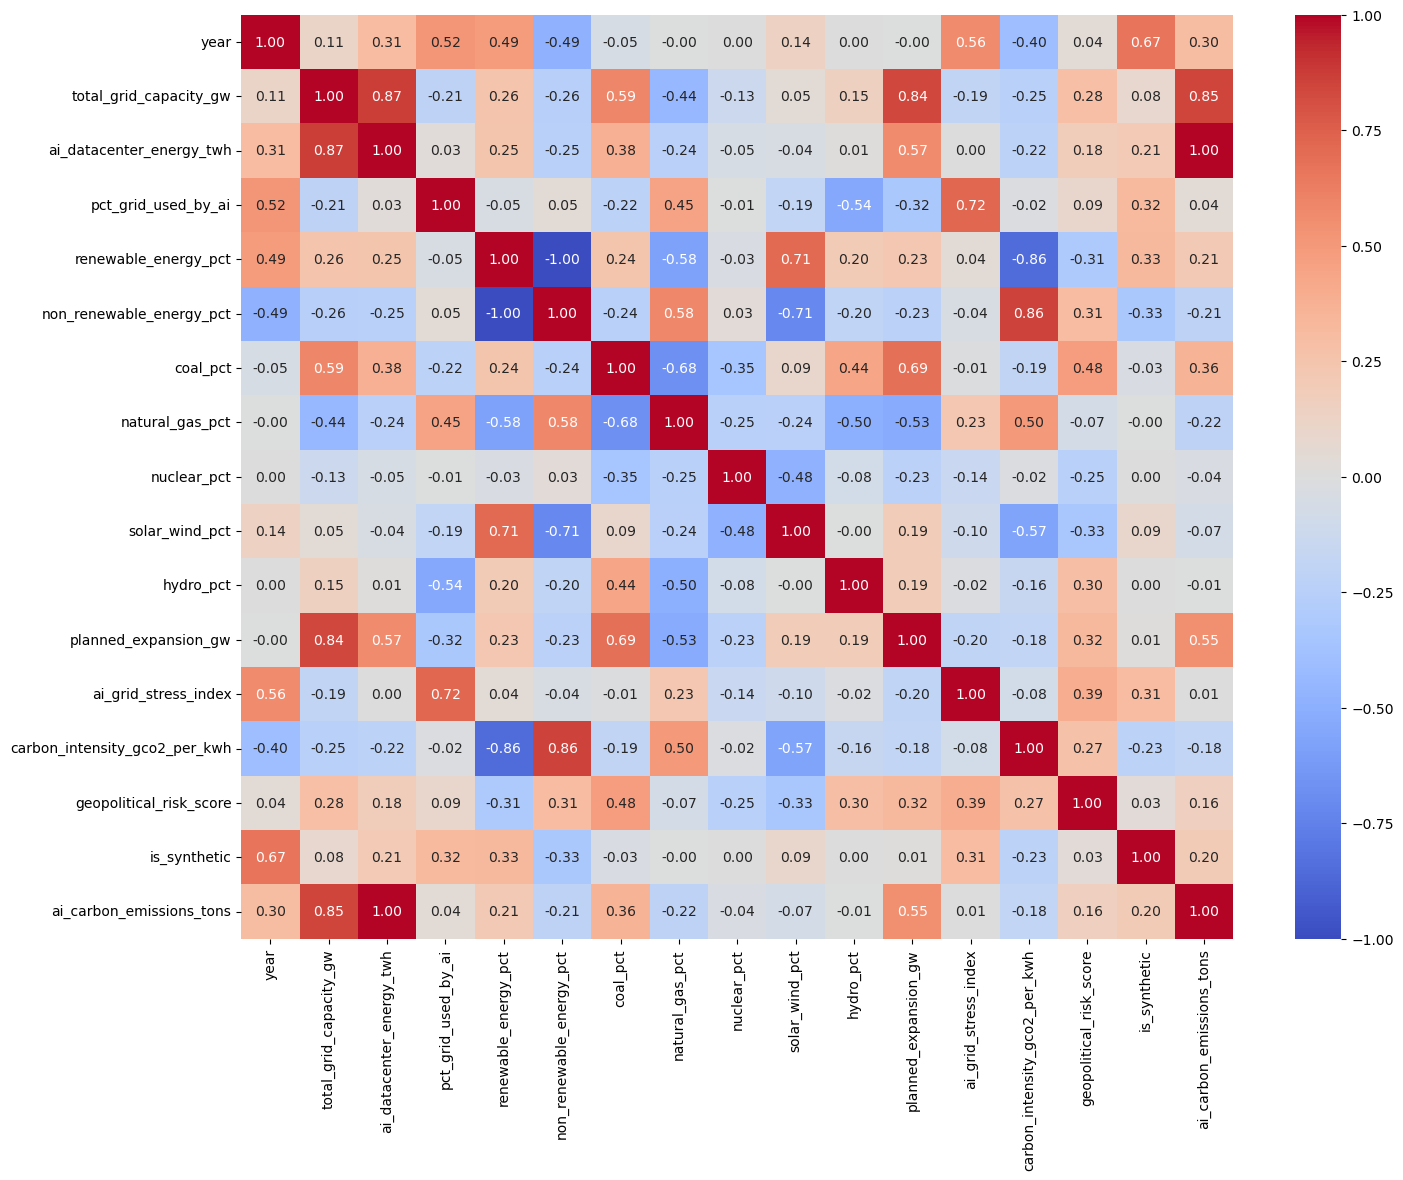

In [54]:
Ecorr=df4.corr(numeric_only=True)
plt.figure(figsize=(16,12))
sns.heatmap(Ecorr,annot=True,cmap='coolwarm',fmt='.2f',)

## 5. macroeconomic_indicators

In [55]:
df5.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 132 entries, 0 to 131
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   macro_id                      132 non-null    object 
 1   country_code                  132 non-null    object 
 2   country                       132 non-null    object 
 3   region                        132 non-null    object 
 4   alliance_bloc                 132 non-null    object 
 5   year                          132 non-null    int64  
 6   gdp_usd_bn                    132 non-null    float64
 7   gdp_growth_rate_pct           132 non-null    float64
 8   inflation_rate_pct            132 non-null    float64
 9   trade_balance_usd_bn          132 non-null    float64
 10  currency_strength_index       132 non-null    float64
 11  tech_sector_pct_gdp           132 non-null    float64
 12  ai_investment_gdp_ratio_pct   132 non-null    float64
 13  dedol

In [56]:
df5.shape

(132, 21)

In [57]:
df5.sample(20)

,macro_id,country_code,country,region,alliance_bloc,year,gdp_usd_bn,gdp_growth_rate_pct,inflation_rate_pct,trade_balance_usd_bn,currency_strength_index,tech_sector_pct_gdp,ai_investment_gdp_ratio_pct,dedollarization_index,foreign_reserves_usd_bn,semiconductor_exports_usd_bn,unemployment_rate_pct,geopolitical_risk_score,ai_sovereignty_index,data_source,is_synthetic
80,MA0081,PK,Pakistan,South Asia,Non-Aligned/SCO,2018,312.3,3.01,5.31,-32.27,47.72,1.28,0.0256,30.76,398.2,0.11,7.73,7.76,9.92,IMF/World Bank/National Statistics/Industry,0
95,MA0096,JP,Japan,Asia-Pacific,Western Alliance,2022,4221.2,0.87,2.60,-149.55,80.22,6.14,0.2843,22.54,28755.1,24.44,3.45,3.03,66.92,IMF/World Bank/National Statistics/Industry,0
48,MA0049,NL,Netherlands,Europe,Western Alliance,2019,912.2,1.10,2.66,72.83,110.23,5.86,0.2192,14.05,331.8,35.58,1.87,2.09,67.88,IMF/World Bank/National Statistics/Industry,0
75,MA0076,SA,Saudi Arabia,Middle East,Non-Aligned,2024,1097.4,2.61,1.77,97.35,99.92,4.55,1.2757,28.41,8240.1,0.94,6.59,5.05,40.78,IMF/World Bank/National Statistics/Industry,1
1,MA0002,US,United States,North America,Western Alliance,2016,18746.4,-0.00,1.25,-528.51,100.04,6.66,0.0640,2.00,1921.5,22.52,5.12,3.07,88.21,IMF/World Bank/National Statistics/Industry,0
97,MA0098,JP,Japan,Asia-Pacific,Western Alliance,2024,4162.0,5.39,2.47,-48.04,84.44,6.74,0.6007,26.14,6609.7,30.55,3.10,3.12,67.65,IMF/World Bank/National Statistics/Industry,1
124,MA0125,TW,Taiwan,Asia-Pacific,Western Alliance,2018,607.2,3.94,1.33,62.34,94.52,23.09,1.1528,12.12,5182.3,87.98,1.69,8.34,84.50,IMF/World Bank/National Statistics/Industry,0
41,MA0042,FR,France,Europe,Western Alliance,2023,3033.8,0.50,5.43,-96.24,108.32,5.03,0.1813,17.66,921.0,6.08,7.07,2.82,64.16,IMF/World Bank/National Statistics/Industry,0
61,MA0062,AE,United Arab Emirates,Middle East,Non-Aligned,2021,411.4,1.72,-0.00,52.12,100.32,4.57,1.2154,27.57,2548.9,1.92,3.65,4.45,44.68,IMF/World Bank/National Statistics/Industry,0
20,MA0021,CN,China,Asia-Pacific,Non-Aligned/SCO,2024,18400.3,3.75,0.51,800.09,95.30,7.89,0.3261,63.14,2378.0,38.92,2.36,8.52,84.45,IMF/World Bank/National Statistics/Industry,1


In [58]:
df5['year'].value_counts()

year
2015    12
2016    12
2017    12
2018    12
2019    12
2020    12
2021    12
2022    12
2023    12
2024    12
2025    12
Name: count, dtype: int64

In [59]:
last_year= df5[df5['year']==2025]
last_year


,macro_id,country_code,country,region,alliance_bloc,year,gdp_usd_bn,gdp_growth_rate_pct,inflation_rate_pct,trade_balance_usd_bn,currency_strength_index,tech_sector_pct_gdp,ai_investment_gdp_ratio_pct,dedollarization_index,foreign_reserves_usd_bn,semiconductor_exports_usd_bn,unemployment_rate_pct,geopolitical_risk_score,ai_sovereignty_index,data_source,is_synthetic
10,MA0011,US,United States,North America,Western Alliance,2025,30049.6,4.80,2.47,-829.06,99.22,11.12,0.5990,2.06,1907.0,65.00,3.34,3.70,95.35,IMF/World Bank/National Statistics/Industry,1
21,MA0022,CN,China,Asia-Pacific,Non-Aligned/SCO,2025,19533.4,4.27,1.01,847.02,95.95,8.16,0.3993,68.23,6448.1,45.60,5.72,8.57,85.76,IMF/World Bank/National Statistics/Industry,1
32,MA0033,DE,Germany,Europe,Western Alliance,2025,4800.6,1.89,1.95,218.98,111.49,5.78,0.2291,14.73,335.1,17.22,5.53,2.53,63.12,IMF/World Bank/National Statistics/Industry,1
43,MA0044,FR,France,Europe,Western Alliance,2025,3220.1,1.85,1.78,-79.56,112.93,5.46,0.2640,18.39,1197.8,8.48,5.16,2.66,64.52,IMF/World Bank/National Statistics/Industry,1
54,MA0055,NL,Netherlands,Europe,Western Alliance,2025,1190.5,-0.30,2.15,98.96,112.12,8.39,0.5040,14.41,279.6,59.79,1.96,2.03,69.55,IMF/World Bank/National Statistics/Industry,1
65,MA0066,AE,United Arab Emirates,Middle East,Non-Aligned,2025,582.2,3.01,1.92,49.84,99.16,6.57,4.2938,40.70,7225.4,3.07,4.55,4.32,50.42,IMF/World Bank/National Statistics/Industry,1
76,MA0077,SA,Saudi Arabia,Middle East,Non-Aligned,2025,1207.1,4.23,1.50,111.59,100.81,5.02,1.6569,30.54,10303.2,1.15,5.44,5.06,41.87,IMF/World Bank/National Statistics/Industry,1
87,MA0088,PK,Pakistan,South Asia,Non-Aligned/SCO,2025,368.6,1.08,14.51,-30.42,28.23,2.80,0.1628,39.52,163.4,0.23,12.72,8.11,12.79,IMF/World Bank/National Statistics/Industry,1
98,MA0099,JP,Japan,Asia-Pacific,Western Alliance,2025,4326.9,2.76,1.92,-31.32,86.08,7.05,0.6933,27.70,33602.7,39.06,1.89,3.25,68.18,IMF/World Bank/National Statistics/Industry,1
109,MA0110,IN,India,South Asia,Non-Aligned,2025,4511.2,3.14,3.82,-271.03,56.70,7.41,0.2660,47.27,9892.5,2.22,3.39,5.01,57.29,IMF/World Bank/National Statistics/Industry,1


In [60]:
last_year_GDP= last_year[['country','gdp_usd_bn']].sort_values(by='gdp_usd_bn',ascending=False).reset_index(drop=True)
last_year_GDP.rename(columns={'gdp_usd_bn':'last_year_gdp'},inplace=True)
last_year_GDP

,country,last_year_gdp
0,United States,30049.6
1,China,19533.4
2,Germany,4800.6
3,India,4511.2
4,Japan,4326.9
5,France,3220.1
6,South Korea,1903.3
7,Saudi Arabia,1207.1
8,Netherlands,1190.5
9,Taiwan,863.1


In [61]:
first_year= df5[df5['year']==2015]
first_year

,macro_id,country_code,country,region,alliance_bloc,year,gdp_usd_bn,gdp_growth_rate_pct,inflation_rate_pct,trade_balance_usd_bn,currency_strength_index,tech_sector_pct_gdp,ai_investment_gdp_ratio_pct,dedollarization_index,foreign_reserves_usd_bn,semiconductor_exports_usd_bn,unemployment_rate_pct,geopolitical_risk_score,ai_sovereignty_index,data_source,is_synthetic
0,MA0001,US,United States,North America,Western Alliance,2015,17925.8,1.00,0.10,-520.58,99.02,6.61,0.0446,1.95,1033.5,22.61,5.36,3.07,87.92,IMF/World Bank/National Statistics/Industry,0
11,MA0012,CN,China,Asia-Pacific,Non-Aligned/SCO,2015,11104.5,3.88,1.46,590.08,94.30,3.91,0.0540,35.31,13581.1,14.70,4.83,7.49,70.23,IMF/World Bank/National Statistics/Industry,0
22,MA0023,DE,Germany,Europe,Western Alliance,2015,3347.3,5.03,0.10,238.11,108.81,3.81,0.0358,14.85,1084.4,5.75,3.55,2.35,58.05,IMF/World Bank/National Statistics/Industry,0
33,MA0034,FR,France,Europe,Western Alliance,2015,2416.2,5.06,0.00,-27.46,108.60,3.55,0.0414,18.49,1117.7,3.32,4.46,2.93,59.68,IMF/World Bank/National Statistics/Industry,0
44,MA0045,NL,Netherlands,Europe,Western Alliance,2015,759.7,0.22,0.19,66.22,108.15,4.54,0.0790,13.74,749.9,23.62,3.85,2.22,66.34,IMF/World Bank/National Statistics/Industry,0
55,MA0056,AE,United Arab Emirates,Middle East,Non-Aligned,2015,370.4,5.13,3.98,20.72,99.03,2.04,0.1350,15.25,661.8,1.17,6.77,4.27,36.03,IMF/World Bank/National Statistics/Industry,0
66,MA0067,SA,Saudi Arabia,Middle East,Non-Aligned,2015,655.7,0.59,2.19,57.88,100.40,1.53,0.0458,7.85,10004.8,0.36,7.90,5.31,30.16,IMF/World Bank/National Statistics/Industry,0
77,MA0078,PK,Pakistan,South Asia,Non-Aligned/SCO,2015,270.4,5.48,4.47,-17.78,54.75,1.01,0.0074,24.88,449.7,0.08,6.14,7.68,9.02,IMF/World Bank/National Statistics/Industry,0
88,MA0089,JP,Japan,Asia-Pacific,Western Alliance,2015,4403.9,5.31,0.80,-10.13,95.41,5.14,0.0454,19.60,35908.3,13.70,3.17,3.12,62.99,IMF/World Bank/National Statistics/Industry,0
99,MA0100,IN,India,South Asia,Non-Aligned,2015,2099.1,6.20,4.86,-123.62,67.98,3.57,0.0143,20.41,12435.3,0.84,9.80,4.97,45.61,IMF/World Bank/National Statistics/Industry,0


In [62]:
first_year_GDP= first_year[['country','gdp_usd_bn']].sort_values(by='gdp_usd_bn',ascending=False).reset_index(drop=True)
first_year_GDP.rename(columns={'gdp_usd_bn':'first_year_gdp'},inplace=True)
first_year_GDP

,country,first_year_gdp
0,United States,17925.8
1,China,11104.5
2,Japan,4403.9
3,Germany,3347.3
4,France,2416.2
5,India,2099.1
6,South Korea,1371.4
7,Netherlands,759.7
8,Saudi Arabia,655.7
9,Taiwan,533.7


In [63]:
cagr= pd.merge(first_year_GDP,last_year_GDP,on='country',how='left')
cagr['cagr']=((cagr['last_year_gdp']/cagr['first_year_gdp'])**(1/10)-1)*100
cagr

,country,first_year_gdp,last_year_gdp,cagr
0,United States,17925.8,30049.6,5.301853
1,China,11104.5,19533.4,5.810285
2,Japan,4403.9,4326.9,-0.176236
3,Germany,3347.3,4800.6,3.671669
4,France,2416.2,3220.1,2.913808
5,India,2099.1,4511.2,7.950807
6,South Korea,1371.4,1903.3,3.331875
7,Netherlands,759.7,1190.5,4.594471
8,Saudi Arabia,655.7,1207.1,6.292790
9,Taiwan,533.7,863.1,4.924375


In [64]:
df5['gdp_growth_rate_pct'].mean().round(2)

np.float64(3.5)

In [65]:
df5['Misery index']= df5['unemployment_rate_pct']+df5['inflation_rate_pct']

In [66]:
fig=px.line(df5,x='year',y='Misery index',color='country')
fig.show()

In [67]:
df5['country'].value_counts()

country
United States           11
China                   11
Germany                 11
France                  11
Netherlands             11
United Arab Emirates    11
Saudi Arabia            11
Pakistan                11
Japan                   11
India                   11
South Korea             11
Taiwan                  11
Name: count, dtype: int64

<Axes: >

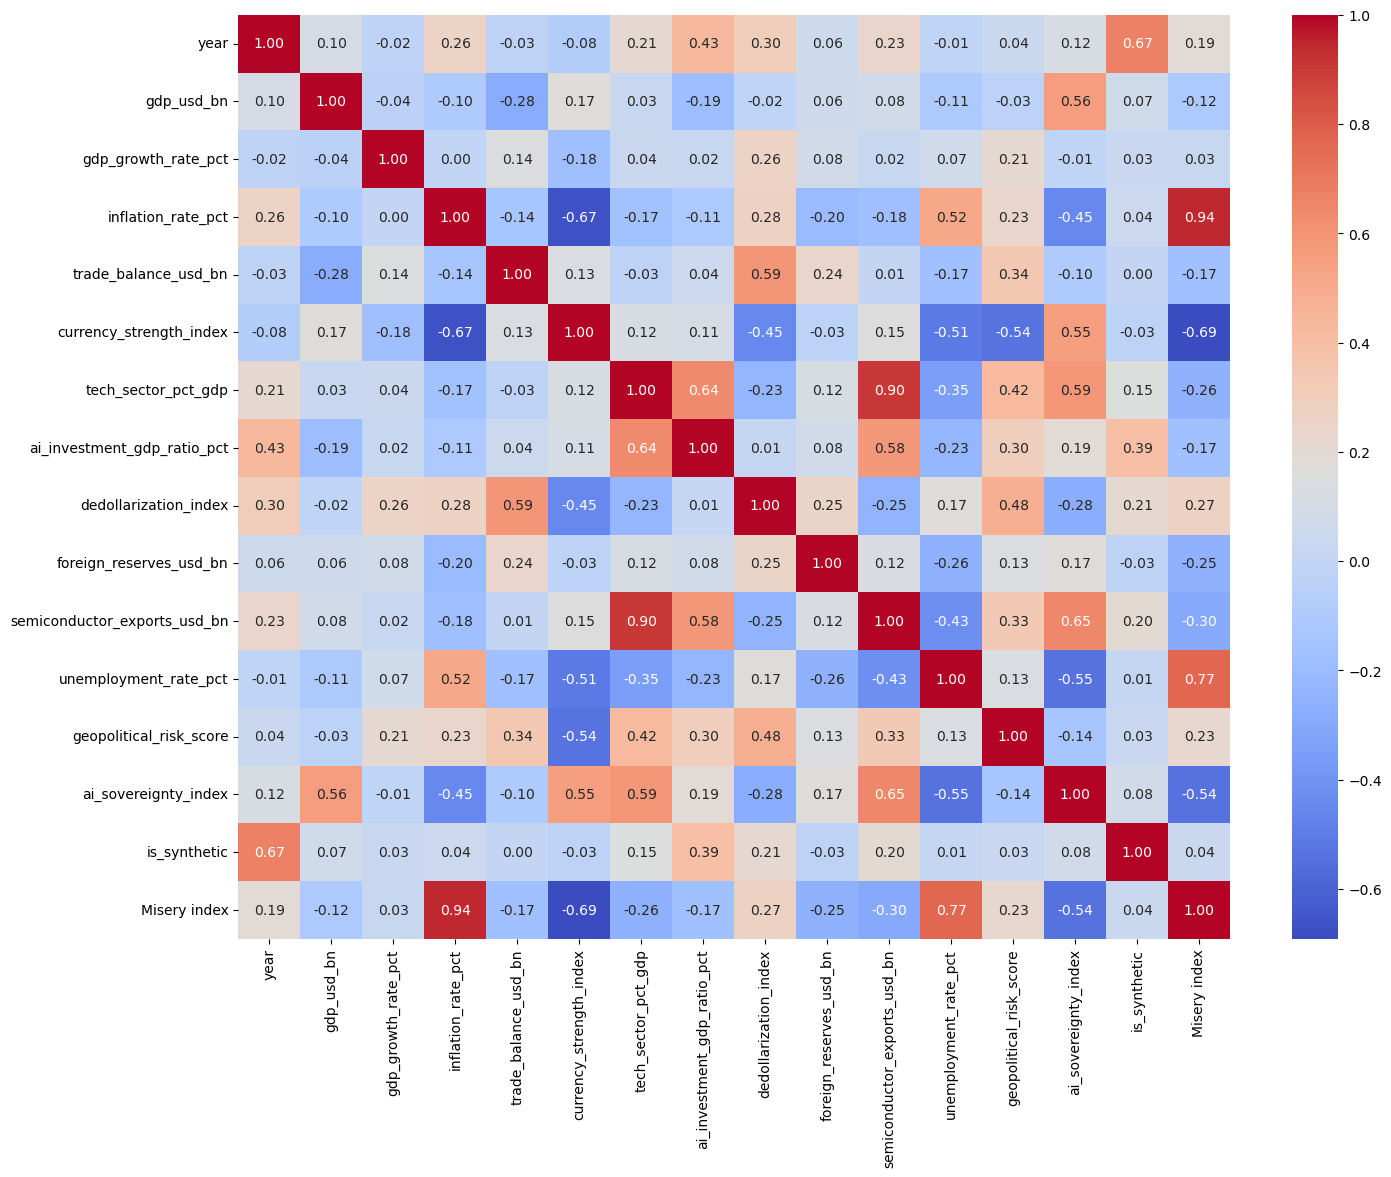

In [68]:
corr=df5.corr(numeric_only=True)
plt.figure(figsize=(16,12))
sns.heatmap(corr,annot=True,cmap='coolwarm',fmt='.2f',)

## 6. company_profiles

In [69]:
df6.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242 entries, 0 to 241
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   company_id             242 non-null    object 
 1   company_name           242 non-null    object 
 2   hq_country_code        242 non-null    object 
 3   hq_country             242 non-null    object 
 4   primary_domain         242 non-null    object 
 5   year_founded           242 non-null    int64  
 6   strategic_focus        242 non-null    object 
 7   year                   242 non-null    int64  
 8   revenue_usd_bn         242 non-null    float64
 9   rd_expenditure_usd_bn  242 non-null    float64
 10  employees              242 non-null    int64  
 11  geopolitical_exposure  242 non-null    object 
 12  sanction_risk_flag     242 non-null    int64  
 13  is_synthetic           242 non-null    int64  
dtypes: float64(2), int64(5), object(7)
memory usage: 26.6+ KB


In [70]:
df6.shape

(242, 14)

In [71]:
df6.sample(20)

,company_id,company_name,hq_country_code,hq_country,primary_domain,year_founded,strategic_focus,year,revenue_usd_bn,rd_expenditure_usd_bn,employees,geopolitical_exposure,sanction_risk_flag,is_synthetic
48,CO0049,Applied Materials,US,United States,Semiconductor Equipment,1967,Deposition Etch Equipment,2019,17.17,2.04,20713,High,0,0
57,CO0058,Lam Research,US,United States,Semiconductor Equipment,1980,Etch Deposition Equipment,2017,8.28,0.76,9680,High,0,0
60,CO0061,Lam Research,US,United States,Semiconductor Equipment,1980,Etch Deposition Equipment,2020,15.00,1.10,13078,High,0,0
34,CO0035,Qualcomm,US,United States,Mobile/Edge AI,1985,Mobile SoC Edge AI,2016,14.92,1.80,30313,High,0,0
213,CO0214,G42,AE,United Arab Emirates,AI Infrastructure,2018,AI Cloud Data Centers,2019,0.77,0.09,2034,Medium,0,0
211,CO0212,G42,AE,United Arab Emirates,AI Infrastructure,2018,AI Cloud Data Centers,2017,0.30,0.02,502,Medium,0,0
19,CO0020,AMD,US,United States,GPU/CPU,1969,GPU CPU Data Center,2023,22.62,5.06,25709,High,0,0
47,CO0048,Applied Materials,US,United States,Semiconductor Equipment,1967,Deposition Etch Equipment,2018,17.15,1.73,21686,High,0,0
145,CO0146,Tokyo Electron,JP,Japan,Semiconductor Equipment,1963,Etch CVD Equipment,2017,9.53,1.30,12852,Medium,0,0
134,CO0135,SK Hynix,KR,South Korea,Memory,1983,DRAM HBM AI Memory,2017,26.65,2.95,28292,Medium,0,0


In [72]:
last_year_employees= df6[df6['year']==2025]

In [73]:
last_year_employees[last_year_employees['company_name']=='AMD']

,company_id,company_name,hq_country_code,hq_country,primary_domain,year_founded,strategic_focus,year,revenue_usd_bn,rd_expenditure_usd_bn,employees,geopolitical_exposure,sanction_risk_flag,is_synthetic
21,CO0022,AMD,US,United States,GPU/CPU,1969,GPU CPU Data Center,2025,28.5,6.19,28413,High,0,1


In [74]:
first_year_employees= df6[df6['year']==2015]

In [75]:
last_emps= last_year_employees[['company_name','hq_country','employees']].sort_values(by='employees',ascending=False).reset_index(drop=True)
last_emps.rename(columns={'employees':'last_year_employees'},inplace=True)
last_emps

,company_name,hq_country,last_year_employees
0,Samsung,South Korea,251349
1,Intel,United States,101670
2,TSMC,Taiwan,80051
3,Qualcomm,United States,51083
4,ASML,Netherlands,48074
5,NVIDIA,United States,45103
6,Micron Technology,United States,42499
7,SK Hynix,South Korea,38382
8,Applied Materials,United States,36236
9,SMIC,China,33401


In [76]:
last_year_GDP= last_year[['country','gdp_usd_bn']].sort_values(by='gdp_usd_bn',ascending=False).reset_index(drop=True)
last_year_GDP.rename(columns={'gdp_usd_bn':'last_year_gdp'},inplace=True)
last_year_GDP

,country,last_year_gdp
0,United States,30049.6
1,China,19533.4
2,Germany,4800.6
3,India,4511.2
4,Japan,4326.9
5,France,3220.1
6,South Korea,1903.3
7,Saudi Arabia,1207.1
8,Netherlands,1190.5
9,Taiwan,863.1


In [77]:
diff_employees= pd.merge(first_year_employees,last_year_employees,on='company_name',how='left')
diff_employees['employees_diff']=diff_employees['employees_y']-diff_employees['employees_x']
diff_employees.sort_values(by='employees_diff',ascending=False)



,company_id_x,company_name,hq_country_code_x,hq_country_x,primary_domain_x,year_founded_x,strategic_focus_x,year_x,revenue_usd_bn_x,rd_expenditure_usd_bn_x,employees_x,geopolitical_exposure_x,sanction_risk_flag_x,is_synthetic_x,company_id_y,hq_country_code_y,hq_country_y,primary_domain_y,year_founded_y,strategic_focus_y,year_y,revenue_usd_bn_y,rd_expenditure_usd_bn_y,employees_y,geopolitical_exposure_y,sanction_risk_flag_y,is_synthetic_y,employees_diff
8,CO0089,ASML,NL,Netherlands,Lithography,1984,EUV DUV Lithography Monopoly,2015,6.24,1.30,12908,Medium,0,0,CO0099,NL,Netherlands,Lithography,1984,EUV DUV Lithography Monopoly,2025,37.64,8.82,48074,Medium,0,1,35166
0,CO0001,NVIDIA,US,United States,GPU/AI Accelerator,1993,GPU AI Training/Inference,2015,4.70,0.84,9942,High,0,0,CO0011,US,United States,GPU/AI Accelerator,1993,GPU AI Training/Inference,2025,177.89,33.20,45103,High,0,1,35161
9,CO0100,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2015,25.43,5.64,45174,High,0,0,CO0110,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2025,107.59,24.05,80051,High,0,1,34877
20,CO0221,Reliance Jio,IN,India,Telecom/AI,2016,AI Infrastructure 5G,2015,0.00,0.00,0,Medium,0,0,CO0231,IN,India,Telecom/AI,2016,AI Infrastructure 5G,2025,25.17,1.29,24736,Medium,0,1,24736
4,CO0045,Applied Materials,US,United States,Semiconductor Equipment,1967,Deposition Etch Equipment,2015,9.50,1.23,14883,High,0,0,CO0055,US,United States,Semiconductor Equipment,1967,Deposition Etch Equipment,2025,31.98,1.91,36236,High,0,1,21353
16,CO0177,SMIC,CN,China,Foundry,2000,Mature Node Foundry 14nm+,2015,2.15,0.27,12108,High,1,0,CO0187,CN,China,Foundry,2000,Mature Node Foundry 14nm+,2025,7.90,0.65,33401,High,1,1,21293
1,CO0012,AMD,US,United States,GPU/CPU,1969,GPU CPU Data Center,2015,3.78,0.65,9602,High,0,0,CO0022,US,United States,GPU/CPU,1969,GPU CPU Data Center,2025,28.50,6.19,28413,High,0,1,18811
19,CO0210,G42,AE,United Arab Emirates,AI Infrastructure,2018,AI Cloud Data Centers,2015,0.10,0.01,101,Medium,0,0,CO0220,AE,United Arab Emirates,AI Infrastructure,2018,AI Cloud Data Centers,2025,12.29,1.81,18007,Medium,0,1,17906
3,CO0034,Qualcomm,US,United States,Mobile/Edge AI,1985,Mobile SoC Edge AI,2015,25.89,2.59,34344,High,0,0,CO0044,US,United States,Mobile/Edge AI,1985,Mobile SoC Edge AI,2025,46.87,4.70,51083,High,0,1,16739
13,CO0144,Tokyo Electron,JP,Japan,Semiconductor Equipment,1963,Etch CVD Equipment,2015,5.84,0.78,10062,Medium,0,0,CO0154,JP,Japan,Semiconductor Equipment,1963,Etch CVD Equipment,2025,28.27,1.93,26051,Medium,0,1,15989


In [78]:
df6[df6['company_name']=='TSMC']

,company_id,company_name,hq_country_code,hq_country,primary_domain,year_founded,strategic_focus,year,revenue_usd_bn,rd_expenditure_usd_bn,employees,geopolitical_exposure,sanction_risk_flag,is_synthetic
99,CO0100,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2015,25.43,5.64,45174,High,0,0
100,CO0101,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2016,30.91,5.49,47577,High,0,0
101,CO0102,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2017,33.18,7.40,47494,High,0,0
102,CO0103,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2018,35.29,5.64,50807,High,0,0
103,CO0104,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2019,34.39,6.03,51604,High,0,0
104,CO0105,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2020,43.49,10.09,56575,High,0,0
105,CO0106,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2021,54.68,8.22,65446,High,0,0
106,CO0107,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2022,72.94,11.55,72653,High,0,0
107,CO0108,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2023,71.70,16.17,77109,High,0,0
108,CO0109,TSMC,TW,Taiwan,Foundry,1987,Advanced Logic 3nm 5nm 7nm,2024,87.68,14.77,78072,High,0,1


In [79]:
px.histogram(df6,x='year',y='employees',barmode='group',color='company_name')

In [80]:
df3.columns

Index(['budget_id', 'country_code', 'country', 'region', 'year',
       'total_ai_investment_usd_bn', 'public_investment_pct',
       'private_investment_pct', 'public_investment_usd_bn',
       'private_investment_usd_bn', 'datacenter_investment_usd_bn',
       'semiconductor_subsidies_usd_bn', 'swf_allocation_usd_bn',
       'ai_workforce_investment_usd_bn', 'strategic_initiative',
       'national_supercomputer_projects', 'foreign_tech_restrictions_active',
       'geopolitical_risk_score', 'ai_sovereignty_index', 'alliance_bloc',
       'data_source', 'is_synthetic'],
      dtype='object')

In [81]:
df1.sample(1)

,trade_id,year,quarter,year_quarter,exporter_country_code,exporter_country,exporter_region,importer_country_code,importer_country,importer_region,hardware_type,hardware_category,volume_units,trade_value_usd_millions,primary_supplier,trade_route,export_control_applied,restriction_factor,geopolitical_sensitivity,geo_risk_score_exporter,geo_risk_score_importer,data_source,is_synthetic
467,TF000468,2021,4,2021-Q4,TW,Taiwan,Asia-Pacific,JP,Japan,Asia-Pacific,DRAM,Standard,5300,331.28,Samsung,Asia-Pacific Maritime,0,1.0,Low,8.31,3.17,UN Comtrade/WITS/SIA Reports,0


In [82]:
df1['exporter_country_code'].value_counts()

exporter_country_code
US    1250
TW     968
KR     880
JP     616
CN     616
NL     446
DE     308
AE     220
IN     132
FR     132
SA      88
Name: count, dtype: Int64

In [83]:
df2['imposing_country'].value_counts()

imposing_country
Netherlands             151
United States           150
South Korea             149
Germany                 141
France                  133
Japan                   130
EU                      121
China                     8
India                     2
Saudi Arabia              1
United Arab Emirates      1
Name: count, dtype: int64

In [84]:
df2['target_country'].value_counts()

target_country
China                   141
Taiwan                  128
RU                      127
India                   124
United Arab Emirates    123
Saudi Arabia            120
Pakistan                107
IR                      103
United States             6
GLOBAL                    5
South Korea               3
Name: count, dtype: int64

In [85]:
country= pd.concat([df1['importer_country'], df1['exporter_country'], df2['imposing_country'], df2['target_country'], df3['country'],df3['alliance_bloc'], df4['country'], df5['country'], df6['hq_country']]).drop_duplicates().reset_index(drop=True)
country_code= pd.concat([df1['importer_country_code'], df1['exporter_country_code'], df2['imposing_country_code'], df2['target_country_code'], df3['country_code'], df4['country_code'], df5['country_code'], df6['hq_country_code']]).drop_duplicates().reset_index(drop=True)
country_df= pd.DataFrame({'country':country,'country_code':country_code})
country_df

,country,country_code
0,United States,US
1,China,CN
2,South Korea,KR
3,Japan,JP
4,Germany,DE
5,India,IN
6,United Arab Emirates,AE
7,France,FR
8,Saudi Arabia,SA
9,Taiwan,TW


In [86]:
dim_country=country_df.merge(
    df3[['country_code', 'alliance_bloc']], 
    on='country_code', 
    how='left'
).drop_duplicates().reset_index(drop=True)
dim_country=dim_country.iloc[:-3]
dim_country['Has full data'] = dim_country.notna().all(axis=1).astype(int)
dim_country

,country,country_code,alliance_bloc,Has full data
0,United States,US,Western Alliance,1
1,China,CN,Non-Aligned/SCO,1
2,South Korea,KR,Western Alliance,1
3,Japan,JP,Western Alliance,1
4,Germany,DE,Western Alliance,1
5,India,IN,Non-Aligned,1
6,United Arab Emirates,AE,Non-Aligned,1
7,France,FR,Western Alliance,1
8,Saudi Arabia,SA,Non-Aligned,1
9,Taiwan,TW,Western Alliance,1


In [87]:
dim_year= pd.DataFrame({'year':list(range(2015,2026))})
dim_year['is_latest_year'] = (dim_year['year'] == 2025).astype(int)
dim_year

,year,is_latest_year
0,2015,0
1,2016,0
2,2017,0
3,2018,0
4,2019,0
5,2020,0
6,2021,0
7,2022,0
8,2023,0
9,2024,0


In [ ]:
with pd.ExcelWriter(r"../excel/Project.xlsx") as writer:
    df1.to_excel(writer, sheet_name='Semiconductor_Trade', index=False)
    df2.to_excel(writer, sheet_name='Trade_Sanctions_Export_Controls', index=False)
    df3.to_excel(writer, sheet_name='National_AI_Infrastructure_Budgets', index=False)
    df4.to_excel(writer, sheet_name='Energy_Grid_Capacity', index=False)
    df5.to_excel(writer, sheet_name='Macroeconomic_Indicators', index=False)
    df6.to_excel(writer, sheet_name='Company_Profiles', index=False)
    dim_country.to_excel(writer, sheet_name='Dim_Country', index=False)
    dim_year.to_excel(writer, sheet_name='Dim_Year', index=False)

c:\Users\mokamed\anaconda3\Lib\site-packages\openpyxl\workbook\child.py:99: UserWarning:

Title is more than 31 characters. Some applications may not be able to read the file

